In [ ]:
Random forest

Accuracy: 0.9167
Precision: 0.9350
Recall: 0.9181
F1_score: 0.9135
Roc_auc: 0.9926


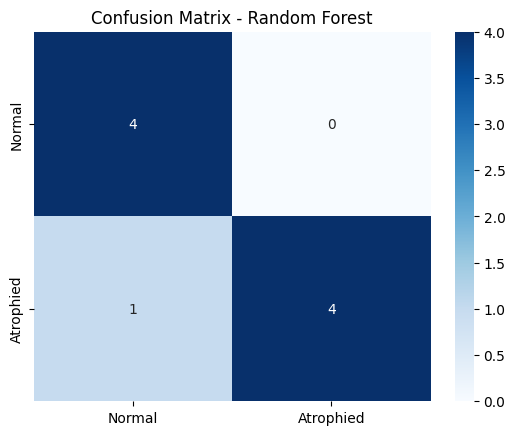

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns



# Load Dataset
file_path = '/content/36.csv'
df = pd.read_csv(file_path)

# Prepare Data
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Model definition
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Cross-validation setup
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro', zero_division=0),
    'recall': make_scorer(recall_score, average='macro', zero_division=0),
    'f1_score': make_scorer(f1_score, average='macro', zero_division=0),
    'roc_auc': 'roc_auc'
}
rskf = RepeatedStratifiedKFold(n_splits=6, n_repeats=5, random_state=42)

# Standardize features
X_scaled = StandardScaler().fit_transform(X)


cv_scores = cross_validate(rf_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Atrophied'], yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - Random Forest')
plt.show()


In [ ]:
XGBoost

Accuracy: 0.8889
Precision: 0.9086
Recall: 0.8917
F1_score: 0.8850
Roc_auc: 0.9370


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [09:05:26] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


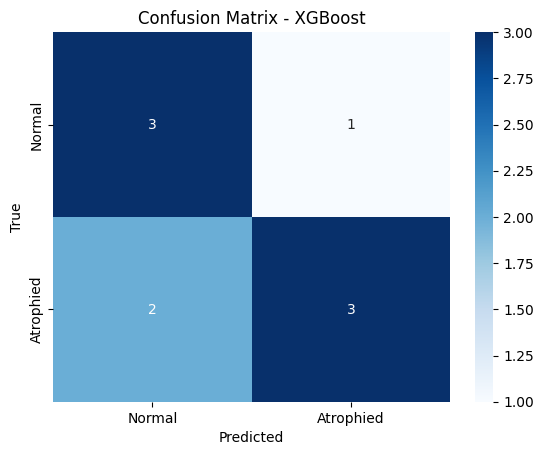

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier

# Load dataset
df = pd.read_csv('/content/36.csv')
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Handle imbalance
xgb_scale_pos_weight = (y == 0).sum() / (y == 1).sum()

# Model
xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss',
    scale_pos_weight=xgb_scale_pos_weight
)

# Cross-validation setup
rskf = RepeatedStratifiedKFold(n_splits=6, n_repeats=5, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1_score': 'f1_macro',
    'roc_auc': 'roc_auc'
}

# Cross-validation
cv_scores = cross_validate(xgb_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Atrophied'], yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [ ]:
SVM

Accuracy: 0.9778
Precision: 0.9833
Recall: 0.9778
F1_score: 0.9771
Roc_auc: 1.0000


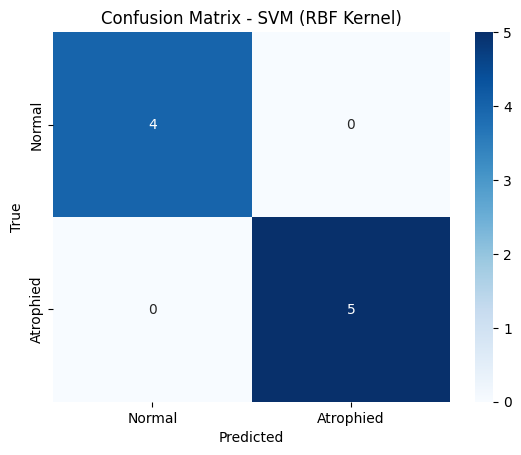

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv('/content/36.csv')
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Cross-validation setup
rskf = RepeatedStratifiedKFold(n_splits=6, n_repeats=5, random_state=42)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1_score': 'f1_macro',
    'roc_auc': 'roc_auc'
}

# Model definition
svm_model = SVC(
    probability=True,
    random_state=42,
    class_weight='balanced',
    kernel='rbf',
    C=1.0
)

# Cross-validation
cv_scores = cross_validate(svm_model, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1)
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
svm_model.fit(X_train, y_train)
y_pred = svm_model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Atrophied'],
            yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - SVM (RBF Kernel)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


In [ ]:
Advanced Random Forest (ARF)

Best Parameters: {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy: 0.9167 ± 0.1032
Precision: 0.9350 ± 0.0833
Recall: 0.9181 ± 0.1023
F1: 0.9135 ± 0.1081
Roc_auc: 0.9926 ± 0.0277


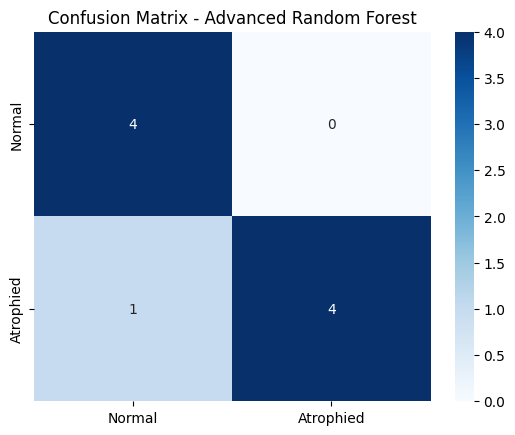

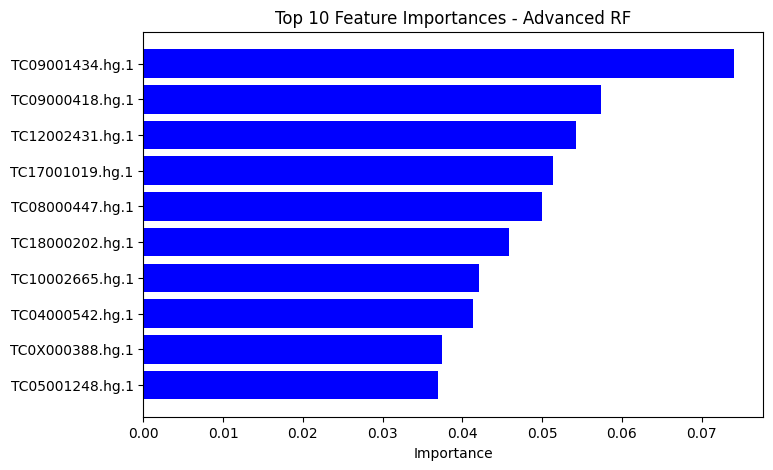

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
file_path = '/content/36.csv'
df = pd.read_csv(file_path)

# Prepare Data
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# Scale features
X_scaled = StandardScaler().fit_transform(X)

# Base RF model
rf = RandomForestClassifier(random_state=42, class_weight="balanced")

# Grid Search with small parameter space
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5, None],
    'min_samples_split': [2, 4],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_scaled, y)

# Best RF model
best_rf = grid_search.best_estimator_
print("Best Parameters:", grid_search.best_params_)

# Cross-validation with variance tracking
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'recall': 'recall_macro',
    'f1': 'f1_macro',
    'roc_auc': 'roc_auc'
}
rskf = RepeatedStratifiedKFold(n_splits=6, n_repeats=5, random_state=42)
cv_scores = cross_validate(best_rf, X_scaled, y, cv=rskf, scoring=scoring, n_jobs=-1, return_estimator=True)

# Show mean + std deviation for robustness
for metric in scoring.keys():
    mean_score = np.mean(cv_scores[f'test_{metric}'])
    std_score = np.std(cv_scores[f'test_{metric}'])
    print(f"{metric.capitalize()}: {mean_score:.4f} ± {std_score:.4f}")

# Train-test split for confusion matrix
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, stratify=y, random_state=42)
best_rf.fit(X_train, y_train)
y_pred = best_rf.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Atrophied'],
            yticklabels=['Normal', 'Atrophied'])
plt.title('Confusion Matrix - Advanced Random Forest')
plt.show()

# 🔹 Feature Importance Plot
importances = best_rf.feature_importances_
indices = np.argsort(importances)[-10:]  # Top 10 important features
plt.figure(figsize=(8, 5))
plt.barh(range(len(indices)), importances[indices], align="center", color='blue')
plt.yticks(range(len(indices)), [feature_cols[i] for i in indices])
plt.xlabel("Importance")
plt.title("Top 10 Feature Importances - Advanced RF")
plt.show()


In [ ]:
Ensemble Voting Classifier with Performance Comparison

Dataset '36.csv' loaded successfully.

--- Running Cross-Validation for Bar Chart Metrics ---
Cross-validating Random Forest for bar chart data...
Cross-validating XGBoost for bar chart data...
Cross-validating SVM (RBF Kernel) for bar chart data...
Cross-validating Ensemble Voting Classifier for bar chart data...

CV Metrics for Bar Chart:
                            Accuracy  Precision    Recall  F1 Score   AUC-ROC
Random Forest               0.916667   0.935000  0.918056  0.913532  0.992593
XGBoost                     0.888889   0.908611  0.891667  0.884960  0.937037
SVM (RBF Kernel)            0.977778   0.983333  0.977778  0.977143  1.000000
Ensemble Voting Classifier  0.938889   0.954167  0.938889  0.937143  0.992593

--- Training Ensemble Model for Confusion Matrix ---
Training ensemble on 27 samples for CM...
Predictions made on 9 samples for CM.


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:183: UserWarning: [05:47:59] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


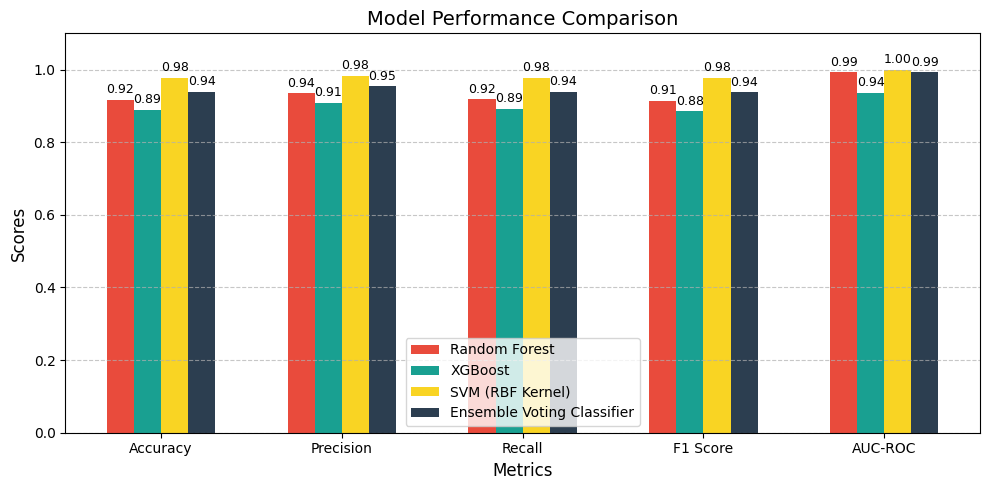

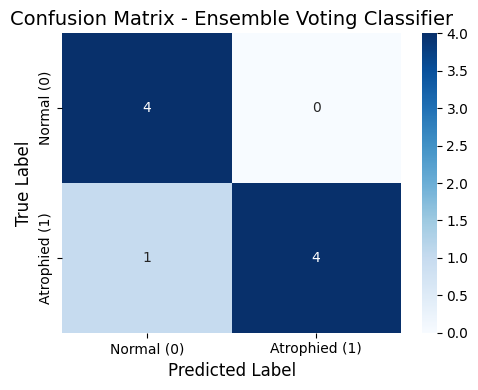

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

# Mount Google Drive (if running in Colab)


# 1. Load the Dataset
file_path = '/content/36.csv'
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: The file was not found at {file_path}")
    exit()

print("Dataset '36.csv' loaded successfully.")

# 2. Prepare Data (X and y)
identifier_cols = ['GSM_ID', 'Subject_ID', 'Group', 'Timepoint']
target_col = 'Target'
feature_cols = [col for col in df.columns if col not in identifier_cols + [target_col]]
X = df[feature_cols]
y = df[target_col]

# --- PART 1: Get Performance Metrics for Bar Chart via Cross-Validation ---
print("\n--- Running Cross-Validation for Bar Chart Metrics ---")
if (y == 1).sum() > 0 and (y == 0).sum() > 0:
    xgb_scale_pos_weight = (y == 0).sum() / (y == 1).sum()
else:
    xgb_scale_pos_weight = 1

# Define models (use consistent definitions)
# IMPORTANT: If you have tuned hyperparameters, update these model definitions!
rf_cv = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
xgb_cv = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=xgb_scale_pos_weight)
svm_cv = SVC(probability=True, random_state=42, class_weight='balanced', kernel='rbf', C=1.0) # RBF Kernel as in image
# Re-define base estimators for the ensemble for CV to ensure they are fresh
rf_ens_cv = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
xgb_ens_cv = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=xgb_scale_pos_weight)
svm_ens_cv = SVC(probability=True, random_state=42, class_weight='balanced', kernel='rbf', C=1.0)
ensemble_cv = VotingClassifier(
    estimators=[('rf', rf_ens_cv), ('xgb', xgb_ens_cv), ('svm', svm_ens_cv)],
    voting='soft'
)

models_for_cv = {
    "Random Forest": rf_cv,
    "XGBoost": xgb_cv,
    "SVM (RBF Kernel)": svm_cv, # Match legend name
    "Ensemble Voting Classifier": ensemble_cv
}

n_splits_cv = 6
n_repeats_cv = 5
rskf_cv = RepeatedStratifiedKFold(n_splits=n_splits_cv, n_repeats=n_repeats_cv, random_state=42)

# Using macro average for precision, recall, F1 as it's common for imbalanced or multi-class
# For binary, 'binary' average could also be used if pos_label is set.
scoring_cv = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro', zero_division=0), # Matched 'Precision' in image
    'recall': make_scorer(recall_score, average='macro', zero_division=0),    # Matched 'Recall' in image
    'f1_score': make_scorer(f1_score, average='macro', zero_division=0), # Matched 'F1 Score' in image
    'roc_auc': 'roc_auc' # Matched 'AUC-ROC' in image (assuming binary)
}

cv_metric_results = defaultdict(lambda: defaultdict(float))
X_scaled_for_cv = StandardScaler().fit_transform(X)

for name, model_instance in models_for_cv.items():
    print(f"Cross-validating {name} for bar chart data...")
    cv_scores = cross_validate(model_instance, X_scaled_for_cv, y, cv=rskf_cv, scoring=scoring_cv, n_jobs=-1, error_score='raise')
    cv_metric_results[name]['Accuracy'] = np.mean(cv_scores['test_accuracy'])
    cv_metric_results[name]['Precision'] = np.mean(cv_scores['test_precision'])
    cv_metric_results[name]['Recall'] = np.mean(cv_scores['test_recall'])
    cv_metric_results[name]['F1 Score'] = np.mean(cv_scores['test_f1_score'])
    cv_metric_results[name]['AUC-ROC'] = np.mean(cv_scores['test_roc_auc'])

# Convert to DataFrame for easier plotting
df_metrics = pd.DataFrame(cv_metric_results).T # Transpose to get models as rows
df_metrics = df_metrics[['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']] # Ensure order
print("\nCV Metrics for Bar Chart:")
print(df_metrics)

# --- PART 2: Train Ensemble Model and Get Predictions for Confusion Matrix ---
print("\n--- Training Ensemble Model for Confusion Matrix ---")
# Split data for CM (this is a SEPARATE split from CV)
# Using a small test size due to only 36 samples overall. 25% -> 9 samples for test.
X_train_cm, X_test_cm, y_train_cm, y_test_cm = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

# Create a pipeline for the ensemble model for CM
# Define base estimators again to ensure they are fresh for this specific training
rf_ens_cm = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
xgb_ens_cm = XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss', scale_pos_weight=xgb_scale_pos_weight)
svm_ens_cm = SVC(probability=True, random_state=42, class_weight='balanced', kernel='rbf', C=1.0)

ensemble_model_for_cm = VotingClassifier(
    estimators=[('rf', rf_ens_cm), ('xgb', xgb_ens_cm), ('svm', svm_ens_cm)],
    voting='soft'
)

pipeline_ensemble_cm = Pipeline([
    ('scaler', StandardScaler()),
    ('ensemble', ensemble_model_for_cm)
])

print(f"Training ensemble on {len(X_train_cm)} samples for CM...")
pipeline_ensemble_cm.fit(X_train_cm, y_train_cm)
y_pred_ensemble_cm = pipeline_ensemble_cm.predict(X_test_cm)
print(f"Predictions made on {len(X_test_cm)} samples for CM.")

# --- PART 3: Plotting ---

# Plot 1: Model Performance Comparison Bar Chart
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
model_names_plot = list(models_for_cv.keys())
n_metrics = len(metrics_to_plot)
n_models = len(model_names_plot)

# Colors similar to the image (approximate)
colors = ['#E94B3C', '#19A091', '#F9D423', '#2C3E50'] # Red, Teal, Yellow, Dark Blue/Grey

bar_width = 0.15
index = np.arange(n_metrics)

fig, ax = plt.subplots(figsize=(10, 5))

for i, model_name in enumerate(model_names_plot):
    scores = df_metrics.loc[model_name, metrics_to_plot].values
    # Offset each model's bars within the group
    # Center of group: index. Offset by -(n_models-1)/2 * bar_width + i * bar_width
    # Simplified: index - (bar_width * (n_models -1) / 2) + (i * bar_width)
    # More general: index + (i - (n_models - 1) / 2) * bar_width
    positions = index + (i - (n_models - 1) / 2) * bar_width
    bars = ax.bar(positions, scores, bar_width, label=model_name, color=colors[i % len(colors)])
    # Add text labels on top of bars
    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.01, f'{yval:.2f}', ha='center', va='bottom', fontsize=9)


ax.set_xlabel('Metrics', fontsize=12)
ax.set_ylabel('Scores', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14)
ax.set_xticks(index)
ax.set_xticklabels(metrics_to_plot)
ax.legend(fontsize=10)
ax.set_ylim(0, 1.1) # Ensure space for labels on top
ax.yaxis.grid(True, linestyle='--', alpha=0.7) # Horizontal grid lines

plt.tight_layout()
plt.show()


# Plot 2: Confusion Matrix for Ensemble Model
cm_ensemble = confusion_matrix(y_test_cm, y_pred_ensemble_cm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_ensemble, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal (0)', 'Atrophied (1)'],
            yticklabels=['Normal (0)', 'Atrophied (1)'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix - Ensemble Voting Classifier', fontsize=14)
plt.tight_layout()
plt.show()

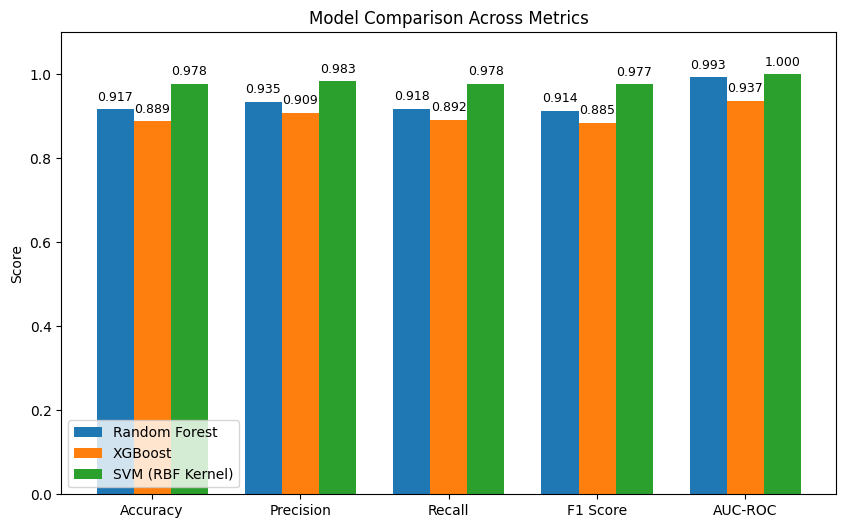

In [ ]:
# Import necessary libraries
import matplotlib.pyplot as plt
import numpy as np

# Data
models = ['Random Forest', 'XGBoost', 'SVM (RBF Kernel)']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']

# Corresponding values for each model
values = [
    [0.916667, 0.935000, 0.918056, 0.913532, 0.992593],  # Random Forest
    [0.888889, 0.908611, 0.891667, 0.884960, 0.937037],  # XGBoost
    [0.977778, 0.983333, 0.977778, 0.977143, 1.000000]   # SVM
]

# Convert to numpy array for easier handling
values = np.array(values)

# Set positions and width for bars
x = np.arange(len(metrics))
width = 0.25  # width of each bar

# Create the bar chart
plt.figure(figsize=(10,6))

plt.bar(x - width, values[0], width, label=models[0])
plt.bar(x, values[1], width, label=models[1])
plt.bar(x + width, values[2], width, label=models[2])

# Add labels, title, and legend
plt.ylabel('Score')
plt.ylim(0, 1.1)  # To give some space above 1
plt.title('Model Comparison Across Metrics')
plt.xticks(x, metrics)
plt.legend()

# Add value labels on top of bars
for i in range(len(metrics)):
    for j in range(3):
        plt.text(x[i] + (j-1)*width, values[j][i]+0.02, f"{values[j][i]:.3f}", ha='center', fontsize=9)

plt.show()


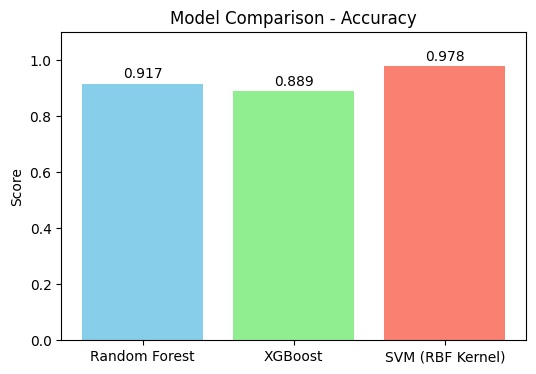

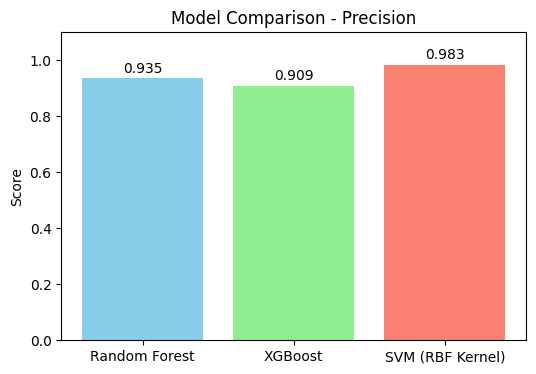

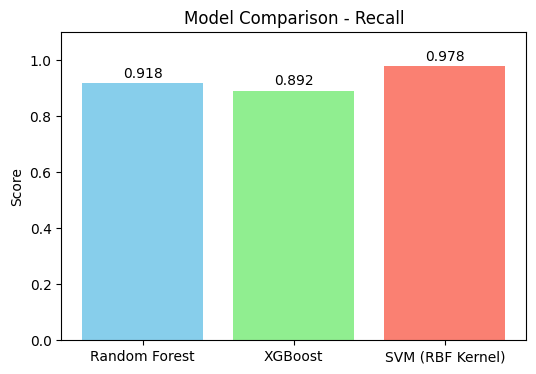

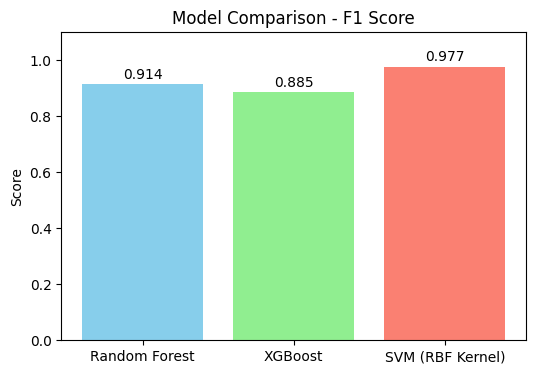

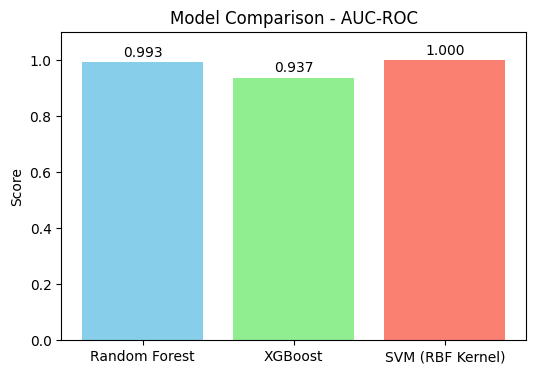

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Models and metrics
models = ['Random Forest', 'XGBoost', 'SVM (RBF Kernel)']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']

# Values for each model
values = np.array([
    [0.916667, 0.935000, 0.918056, 0.913532, 0.992593],  # Random Forest
    [0.888889, 0.908611, 0.891667, 0.884960, 0.937037],  # XGBoost
    [0.977778, 0.983333, 0.977778, 0.977143, 1.000000]   # SVM
])

# Generate a separate plot for each metric
for i, metric in enumerate(metrics):
    plt.figure(figsize=(6,4))
    plt.bar(models, values[:, i], color=['skyblue', 'lightgreen', 'salmon'])
    plt.ylim(0, 1.1)
    plt.ylabel('Score')
    plt.title(f'Model Comparison - {metric}')

    # Add value labels on top of bars
    for j, val in enumerate(values[:, i]):
        plt.text(j, val + 0.02, f"{val:.3f}", ha='center', fontsize=10)

    plt.show()
